<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/RNN_P8_LSTM_Implemenation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Implementing the LSTM from Scratch

Now we translate the LSTM equations into TensorFlow code.

Unlike a built-in LSTM layer, we will manually create the parameters for each of the **three gates** and the **candidate memory**.

Each component needs:

- weights for the current input $X_t$
- weights for the previous hidden state $H_{t-1}$
- a bias

So we create four parameter groups:

| Component | Input weights | Hidden-state weights | Bias |
|---|---|---|---|
| Input gate | $W_{xi}$ | $W_{hi}$ | $b_i$ |
| Forget gate | $W_{xf}$ | $W_{hf}$ | $b_f$ |
| Output gate | $W_{xo}$ | $W_{ho}$ | $b_o$ |
| Candidate memory | $W_{xc}$ | $W_{hc}$ | $b_c$ |

The weights are initialized to small random values and the biases to zero.

> **Key idea:** These are the parameters the LSTM will learn during training. Each gate has its own weights because each gate must learn a different decision.

In [ ]:
!pip install --q D2l --no-deps

In [ ]:
import tensorflow as tf
from d2l import tensorflow as d2l


In [ ]:
class LSTMScratch(d2l.Module):
    def __init__(self, num_inputs, num_hiddens, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()

        # Create a trainable weight matrix.
        # add_weight() is used instead of tf.Variable()
        # so current Keras correctly tracks the parameter.
        def init_weight(shape, name):
            return self.add_weight(
                name=name,
                shape=shape,
                initializer=tf.keras.initializers.RandomNormal(
                    mean=0.0,
                    stddev=sigma
                ),
                trainable=True
            )

        # Every LSTM component needs:
        # 1. weights from X_t
        # 2. weights from H_{t-1}
        # 3. a bias
        def triple(name):
            W_x = init_weight(
                (num_inputs, num_hiddens),
                f"W_x{name}"
            )

            W_h = init_weight(
                (num_hiddens, num_hiddens),
                f"W_h{name}"
            )

            b = self.add_weight(
                name=f"b_{name}",
                shape=(num_hiddens,),
                initializer="zeros",
                trainable=True
            )

            return W_x, W_h, b

        # Input gate parameters
        self.W_xi, self.W_hi, self.b_i = triple("i")

        # Forget gate parameters
        self.W_xf, self.W_hf, self.b_f = triple("f")

        # Output gate parameters
        self.W_xo, self.W_ho, self.b_o = triple("o")

        # Candidate-memory parameters
        self.W_xc, self.W_hc, self.b_c = triple("c")

### Forward Pass: Putting the LSTM Together

The `forward()` method implements the equations we just studied.

At the beginning, both states are initialized to zero:

- $H$ → hidden state
- $C$ → cell state (memory)

Then, for every time step, the LSTM performs the following sequence:

**1. Compute the three gates**

$$
I_t = \sigma(X_tW_{xi} + H_{t-1}W_{hi} + b_i)
$$

$$
F_t = \sigma(X_tW_{xf} + H_{t-1}W_{hf} + b_f)
$$

$$
O_t = \sigma(X_tW_{xo} + H_{t-1}W_{ho} + b_o)
$$

**2. Create candidate information**

$$
\tilde{C}_t = \tanh(X_tW_{xc} + H_{t-1}W_{hc} + b_c)
$$

**3. Update the memory**

$$
C_t = F_t \odot C_{t-1} + I_t \odot \tilde{C}_t
$$

In words:

`new memory = kept old memory + selected new information`

**4. Compute the hidden state**

$$
H_t = O_t \odot \tanh(C_t)
$$

The hidden state $H_t$ is added to `outputs`, while both $H_t$ and $C_t$ are carried to the next time step.

> **The code is simply the LSTM diagram translated into equations and then into TensorFlow operations.**

In [ ]:
@d2l.add_to_class(LSTMScratch)
def forward(self, inputs, H_C=None):

    # ---------------------------------------------------------
    # 1. Initialize the two states of the LSTM
    # ---------------------------------------------------------
    # H = hidden state: information being used/output now
    # C = cell state:   the LSTM's internal memory
    #
    # If this is the beginning of a sequence, there is no
    # previous memory, so both H and C start at zero.
    if H_C is None:
        # Shape: (batch_size, num_hiddens)
        H = tf.zeros((inputs.shape[1], self.num_hiddens))
        C = tf.zeros((inputs.shape[1], self.num_hiddens))
    else:
        # Otherwise, continue from the previous H and C
        H, C = H_C

    # Store the hidden state produced at each time step
    outputs = []

    # ---------------------------------------------------------
    # 2. Process the sequence one time step at a time
    # ---------------------------------------------------------
    # X is the current input X_t.
    # H and C initially represent H_{t-1} and C_{t-1}.
    for X in inputs:

        # INPUT GATE
        # How much NEW information should be allowed into memory?
        #
        # I_t = sigmoid(X_t W_xi + H_{t-1} W_hi + b_i)
        I = tf.sigmoid(
            tf.matmul(X, self.W_xi) +
            tf.matmul(H, self.W_hi) +
            self.b_i
        )

        # FORGET GATE
        # How much of the OLD memory C_{t-1} should be kept?
        #
        # F_t = sigmoid(X_t W_xf + H_{t-1} W_hf + b_f)
        F = tf.sigmoid(
            tf.matmul(X, self.W_xf) +
            tf.matmul(H, self.W_hf) +
            self.b_f
        )

        # OUTPUT GATE
        # How much of the updated memory should be used
        # to create the current hidden state H_t?
        #
        # O_t = sigmoid(X_t W_xo + H_{t-1} W_ho + b_o)
        O = tf.sigmoid(
            tf.matmul(X, self.W_xo) +
            tf.matmul(H, self.W_ho) +
            self.b_o
        )

        # CANDIDATE MEMORY (input node)
        # Create the NEW information that could be added to memory.
        #
        # C~_t = tanh(X_t W_xc + H_{t-1} W_hc + b_c)
        C_tilde = tf.tanh(
            tf.matmul(X, self.W_xc) +
            tf.matmul(H, self.W_hc) +
            self.b_c
        )

        # -----------------------------------------------------
        # 3. Update the cell state (memory)
        # -----------------------------------------------------
        # New memory = kept old memory + selected new information
        #
        # C_t = F_t * C_{t-1} + I_t * C~_t
        C = F * C + I * C_tilde

        # -----------------------------------------------------
        # 4. Compute the new hidden state
        # -----------------------------------------------------
        # Use the output gate to decide how much of the
        # current memory should be used right now.
        #
        # H_t = O_t * tanh(C_t)
        H = O * tf.tanh(C)

        # Save H_t as the output for this time step
        outputs.append(H)

    # ---------------------------------------------------------
    # 5. Return the results
    # ---------------------------------------------------------
    # outputs = hidden states from ALL time steps
    # H       = final hidden state
    # C       = final cell state (memory)
    #
    # Final H and C can be passed into the next sequence.
    return outputs, (H, C)

In [ ]:
def d2l_rnn_loss(Y_hat, Y):

    # ---------------------------------------------------------
    # 1. Reshape the model predictions
    # ---------------------------------------------------------
    # Y_hat contains the model's prediction scores (logits)
    # for every character at every time step.
    #
    # Original idea:
    # (batch_size, num_steps, vocab_size)
    #
    # Cross-entropy expects one row of scores per prediction,
    # so combine batch_size and num_steps into one dimension:
    #
    # (batch_size * num_steps, vocab_size)
    Y_hat = tf.reshape(
        Y_hat,
        (-1, Y_hat.shape[-1])
    )

    # ---------------------------------------------------------
    # 2. Reshape the correct next-character targets
    # ---------------------------------------------------------
    # Y contains the actual next-character ID for each
    # position in each sequence.
    #
    # Original idea:
    # (batch_size, num_steps)
    #
    # Flatten into:
    # (batch_size * num_steps,)
    Y = tf.reshape(
        Y,
        (-1,)
    )

    # ---------------------------------------------------------
    # 3. Define the loss function
    # ---------------------------------------------------------
    # SparseCategoricalCrossentropy is appropriate because:
    #
    # Y     -> contains the correct character ID
    # Y_hat -> contains one score for EVERY character
    #          in the vocabulary
    #
    # from_logits=True means Y_hat contains raw scores,
    # so TensorFlow will handle the softmax internally.
    loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    )

    # ---------------------------------------------------------
    # 4. Compare predictions with the correct characters
    # ---------------------------------------------------------
    # A lower loss means the model is assigning higher
    # scores/probabilities to the correct next characters.
    return loss_fn(Y, Y_hat)

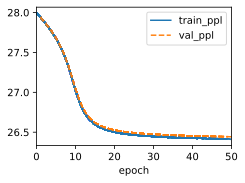

In [ ]:
# ---------------------------------------------------------
# 1. Load and prepare the Time Machine dataset
# ---------------------------------------------------------
# batch_size = 1024:
#   Train on 1024 sequences at the same time.
#
# num_steps = 32:
#   Each sequence contains 32 characters/time steps.
data = d2l.TimeMachine(
    batch_size=1024,
    num_steps=32
)


# Use GPU if one is available
with d2l.try_gpu():

    # -----------------------------------------------------
    # 2. Create our LSTM
    # -----------------------------------------------------
    # num_inputs = number of unique characters in the vocabulary.
    # Each character is represented as a one-hot vector whose
    # length equals the vocabulary size.
    #
    # num_hiddens = 32:
    # H_t and C_t each contain 32 values.
    lstm = LSTMScratch(
        num_inputs=len(data.vocab),
        num_hiddens=32
    )


    # -----------------------------------------------------
    # 3. Turn the LSTM into a language model
    # -----------------------------------------------------
    # The LSTM produces hidden states H_t.
    #
    # RNNLMScratch adds the output layer that converts each
    # H_t into one score for EVERY possible next character.
    #
    # If the vocabulary has 28 characters:
    #       H_t (32 values) -> output layer -> 28 scores
    model = d2l.RNNLMScratch(
        lstm,
        vocab_size=len(data.vocab),
        lr=4.0
    )


    # -----------------------------------------------------
    # 4. Attach our cross-entropy loss
    # -----------------------------------------------------
    # This compares the model's predicted scores with the
    # actual next character from the book.
    #
    # We attach it AFTER creating model because model must
    # already exist before we can assign model.loss.
    model.loss = d2l_rnn_loss


    # -----------------------------------------------------
    # 5. Configure the training process
    # -----------------------------------------------------
    # max_epochs = 50:
    #   Go through the training process for 50 epochs.
    #
    # gradient_clip_val = 1:
    #   Clip very large gradients to help prevent
    #   exploding gradients during BPTT.
    trainer = d2l.Trainer(
        max_epochs=50,
        gradient_clip_val=1
    )


    # -----------------------------------------------------
    # 6. Train the LSTM language model
    # -----------------------------------------------------
    # During training:
    #
    # characters
    #     ↓
    # LSTM
    #     ↓
    # predicted next-character scores
    #     ↓
    # cross-entropy loss
    #     ↓
    # BPTT
    #     ↓
    # update the learned weights
    trainer.fit(model, data)

## Hands-On Investigation: What Affects LSTM Learning?

We have implemented an LSTM from scratch. Now we will investigate how several design choices affect its learning behavior.

For each experiment:

1. **Predict** what you expect to happen before running the model.
2. Change **only one parameter at a time**.
3. Retrain the model.
4. Compare the training curve and final **perplexity** with the baseline.
5. Explain whether the result supports your prediction.

### Baseline

`lr = 4.0` &nbsp;&nbsp; `num_hiddens = 32` &nbsp;&nbsp; `num_steps = 32`

---

### Experiment 1 — Learning Rate

Try:

`lr = 2.0` and `lr = 1.0`

**Before running:** Predict how reducing the learning rate will affect:

- speed of convergence
- stability of training
- final perplexity

**After running:** Was your prediction correct? Explain.

---

### Experiment 2 — Model Capacity

Change:

`num_hiddens = 32` → `num_hiddens = 64`

**Before running:** Predict whether increasing the hidden-state size will necessarily improve performance.

**After running:** Compare perplexity and training behavior.

**Discuss:** Why might a larger LSTM not automatically produce a better model?

---

### Experiment 3 — Sequence Length

Change:

`num_steps = 32` → `16` or `64`

**Before running:** Consider what information becomes available to the LSTM when the training sequences are shorter or longer.

**After running:** Compare training behavior and perplexity.

**Discuss:** What is the trade-off between longer temporal context and computational cost?

---

### Record Your Results

| Experiment | Setting | Predicted Effect | Final Perplexity | Interpretation |
|---|---|---|---:|---|
| Baseline | `lr=4.0, hidden=32, steps=32` | — | | |
| Learning Rate | `lr=2.0` | | | |
| Learning Rate | `lr=1.0` | | | |
| Model Capacity | `hidden=64` | | | |
| Sequence Length | `steps=16` | | | |
| Sequence Length | `steps=64` | | | |

### Research Question

**Which factor had the strongest effect on learning behavior, and what does your experiment suggest about the relationship between optimization, model capacity, and temporal context in LSTMs?**

> The objective is not to find the "best" configuration. The objective is to use controlled experiments to understand **why the model behaves differently when its design or training conditions change**.

Concise Implementation of LSTM

So far, we built the LSTM **from scratch** to understand what happens inside the memory cell:

- Input gate $I_t$
- Forget gate $F_t$
- Output gate $O_t$
- Candidate memory $\tilde{C}_t$
- Cell state $C_t$
- Hidden state $H_t$

For example, we explicitly programmed:

$$
C_t = F_t \odot C_{t-1} + I_t \odot \tilde{C}_t
$$

and

$$
H_t = O_t \odot \tanh(C_t)
$$

### But do we normally implement all of this ourselves?

**No.**

In practice, deep-learning frameworks such as TensorFlow provide a ready-made LSTM layer:

`tf.keras.layers.LSTM(...)`

This layer internally creates and learns the **same gates, weights, biases, cell state, and hidden state** that we implemented manually.





Now we use TensorFlow's implementation to see **how we would actually use an LSTM in practice**.

In [ ]:
class LSTM(d2l.RNN):
    def __init__(self, num_hiddens):
        d2l.Module.__init__(self)
        self.save_hyperparameters()


        self.rnn = tf.keras.layers.LSTM(
            num_hiddens,
            return_sequences=True,
            return_state=True
        )

    def forward(self, inputs, H_C=None):

        # D2L gives: (time_steps, batch_size, features)
        # Keras expects: (batch_size, time_steps, features)
        inputs = tf.transpose(inputs, [1, 0, 2])

        # Run the LSTM
        outputs, H, C = self.rnn(
            inputs,
            initial_state=H_C
        )

        # Convert back to D2L format
        # (batch_size, time_steps, hidden)
        # -> (time_steps, batch_size, hidden)
        outputs = tf.transpose(outputs, [1, 0, 2])

        return outputs, (H, C)


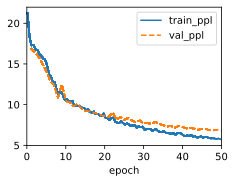

In [ ]:
lstm = LSTM(num_hiddens=32)

with d2l.try_gpu():

    model = d2l.RNNLM(
        lstm,
        vocab_size=len(data.vocab),
        lr=4.0
    )

    # Attach the same D2L-compatible loss
    model.loss = d2l_rnn_loss

    trainer.fit(model, data)

### Generating Text with the Trained LSTM

After training the LSTM, we can use it to generate new text:



In [ ]:
model.predict('it has', 20, data.vocab)


'it has a coully some the t'